# Checking `subtract_low_signal_noise_background` against `constbacksub`

This notebook compares three versions of the constant background subtraction:

- **reference**: a line-by-line numpy transcription of radiospectra's `Spectrogram.constbacksub`
  (array shaped *(freq, time)*)
- **new**: `ecallisto_ng.data_processing.utils.subtract_low_signal_noise_background` from this
  checkout's `src/` (branch `fix/constbacksub-parity`)
- **old**: a verbatim copy of the function as it was on `main` before the fix

Note on orientation: ecallisto_ng DataFrames have **time as index (rows)** and **frequency as
columns**, i.e. the transpose of the radiospectra array. So "mean over time of each channel" is
`df.mean(axis=0)` here and `np.average(im, axis=1)` in radiospectra.

Change `FITS_FILE` below to try another observation.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.io import fits

# Use the code from this checkout, not an installed copy of ecallisto_ng
REPO = Path.cwd().resolve().parent if Path.cwd().name == "example" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import ecallisto_ng
from ecallisto_ng.data_processing.utils import subtract_low_signal_noise_background

print("ecallisto_ng imported from:", ecallisto_ng.__file__)
assert str(REPO / "src") in ecallisto_ng.__file__, "not using this checkout's src/"

FITS_FILE = "/Users/csillag/Projects/eCallistoValidation/Calibrarion_with_Orfees/eca_files/BIR_20151104_120000_05.fit.gz"
PERCENTILE = 0.05

ModuleNotFoundError: No module named 'numpy'

## The three implementations

In [ ]:
def constbacksub_reference(im, percentile=0.05):
    """Numpy transcription of radiospectra Spectrogram.constbacksub; im is (freq, time)."""
    im = im.copy()
    nx, ny = im.shape
    average_arr = np.average(im, axis=1)
    for i in range(nx):
        im[i, :] = im[i, :] - average_arr[i]
    sdev_arr = np.zeros(ny)
    for i in range(ny):
        sdev_arr[i] = np.std(im[:, i])
    zist = np.argsort(sdev_arr, kind="stable")
    nPart = int(ny * percentile)
    zist = zist[0: nPart + 1]
    background = np.average(im[:, zist], axis=1)
    for j in range(ny):
        im[:, j] = im[:, j] - background
    return im, np.sort(zist)


def old_subtract_low_signal_noise_background(df, percentile=0.05):
    """Verbatim copy of the function on main before the fix."""
    df_ = df.copy()
    row_averages = df_.mean(axis=1)
    df_ = df_.sub(row_averages, axis=0)
    column_sdevs = df_.std(axis=1)
    n_columns = len(column_sdevs)
    n_background = int(n_columns * percentile)
    background_cols = column_sdevs.nsmallest(n_background).index
    background = df_.loc[background_cols].mean()
    return df - background


# Which time samples each version treats as "quiet" (positions along the time axis)
def selected_new(df, percentile=0.05):
    df_ = df - df.mean(axis=0)
    s = df_.std(axis=1, ddof=0).reset_index(drop=True)
    return np.sort(s.nsmallest(int(len(s) * percentile) + 1).index.to_numpy())


def selected_old(df, percentile=0.05):
    s = df.sub(df.mean(axis=1), axis=0).std(axis=1).reset_index(drop=True)
    return np.sort(s.nsmallest(int(len(s) * percentile)).index.to_numpy())

: 

## Load the FITS file into an ecallisto_ng-style DataFrame (time × frequency)

In [3]:
with fits.open(FITS_FILE) as hdul:
    im = hdul[0].data.astype(float)            # (freq, time)
    hdr = hdul[0].header
    freqs = hdul[1].data["FREQUENCY"][0].astype(float)  # FITS is big-endian; pandas needs native
    times = hdul[1].data["TIME"][0].astype(float)

start = pd.Timestamp(hdr["DATE-OBS"].replace("/", "-") + " " + hdr["TIME-OBS"])
index = start + pd.to_timedelta(times, unit="s")
df = pd.DataFrame(im.T, index=index, columns=freqs)   # time on index, frequency on columns
print(hdr.get("INSTRUME"), start, "| df shape (time, freq):", df.shape)
df.iloc[:3, :5]

BIR 2015-11-04 12:00:00.637000 | df shape (time, freq): (3600, 200)


,93.750000,93.500000,92.750000,92.313004,92.063004
2015-11-04 12:00:00.637,187.0,195.0,189.0,196.0,172.0
2015-11-04 12:00:00.887,185.0,193.0,189.0,195.0,171.0
2015-11-04 12:00:01.137,186.0,192.0,186.0,193.0,173.0


## Run all three and compare numerically

In [4]:
ref_im, ref_sel = constbacksub_reference(df.to_numpy().T, PERCENTILE)
ref = pd.DataFrame(ref_im.T, index=df.index, columns=df.columns)
new = subtract_low_signal_noise_background(df, percentile=PERCENTILE)
old = old_subtract_low_signal_noise_background(df, percentile=PERCENTILE)

new_sel, old_sel = selected_new(df, PERCENTILE), selected_old(df, PERCENTILE)

print(f"max |new - reference| = {np.nanmax(np.abs(new - ref).to_numpy()):.3e}")
print(f"max |old - reference| = {np.nanmax(np.abs(old - ref).to_numpy()):.3f}")
# Both subtract one constant per channel, so old - reference is constant in time
offset = (old - ref).mean(axis=0)
print(f"old - reference is a per-channel constant between "
      f"{offset.min():.1f} and {offset.max():.1f} counts (spread {offset.max() - offset.min():.1f})")
print()
print(f"selected time samples: reference {len(ref_sel)}, new {len(new_sel)}, old {len(old_sel)}")
print(f"new ∩ reference: {len(np.intersect1d(new_sel, ref_sel))}")
print(f"old ∩ reference: {len(np.intersect1d(old_sel, ref_sel))}")

max |new - reference| = 3.775e-15
max |old - reference| = 191.828
old - reference is a per-channel constant between 179.6 and 191.8 counts (spread 12.2)

selected time samples: reference 181, new 181, old 180
new ∩ reference: 181
old ∩ reference: 3


## Spectrograms

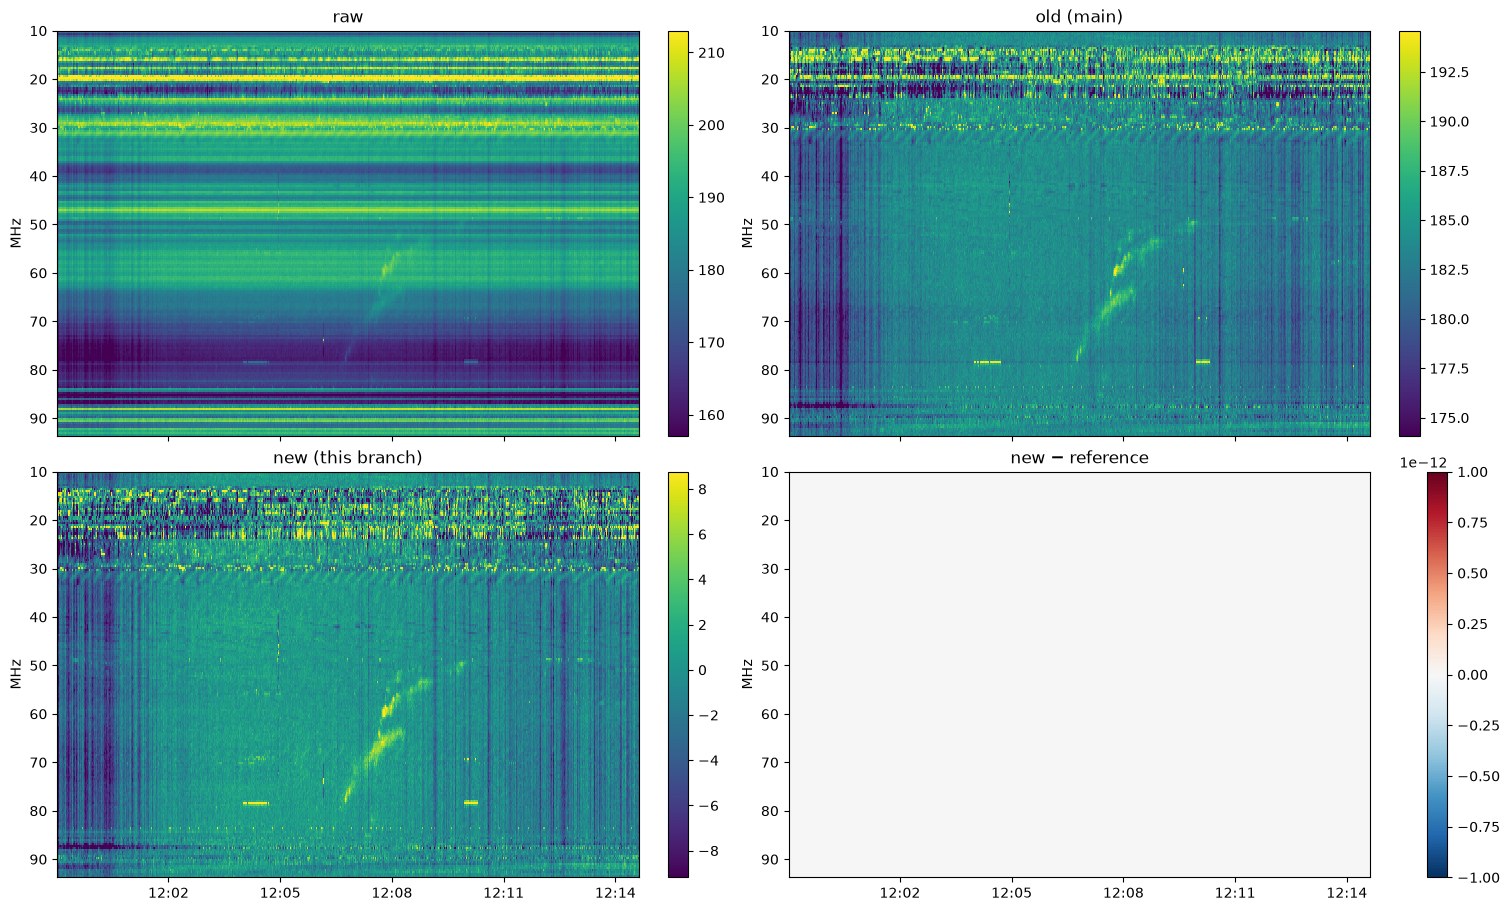

In [5]:
def show(ax, data, title, vlim=None, cmap="viridis"):
    t = mdates.date2num(data.index.to_pydatetime())
    f = data.columns.to_numpy(dtype=float)
    vals = data.to_numpy().T
    if vlim is None:
        vlim = np.nanpercentile(vals, [1, 99])
    img = ax.imshow(vals, aspect="auto", origin="upper" if f[0] > f[-1] else "lower",
                    extent=[t[0], t[-1], min(f[-1], f[0]), max(f[-1], f[0])],
                    vmin=vlim[0], vmax=vlim[1], cmap=cmap, interpolation="nearest")
    if f[0] > f[-1]:
        ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_title(title); ax.set_ylabel("MHz")
    plt.colorbar(img, ax=ax)
    return t

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
vlim = np.nanpercentile(ref.to_numpy(), [1, 99.5])
show(axes[0, 0], df, "raw")
show(axes[0, 1], old, "old (main)", vlim=np.nanpercentile(old.to_numpy(), [1, 99.5]))
show(axes[1, 0], new, "new (this branch)", vlim=vlim)
d = new - ref
m = max(np.nanmax(np.abs(d.to_numpy())), 1e-12)
show(axes[1, 1], d, "new − reference", vlim=(-m, m), cmap="RdBu_r")
plt.show()

## Which time samples are selected as background?

Top: std across frequency of the channel-mean-subtracted data for each time sample (what the
reference ranks), with the samples chosen by each version. Bottom: the new result with the
selected samples marked.

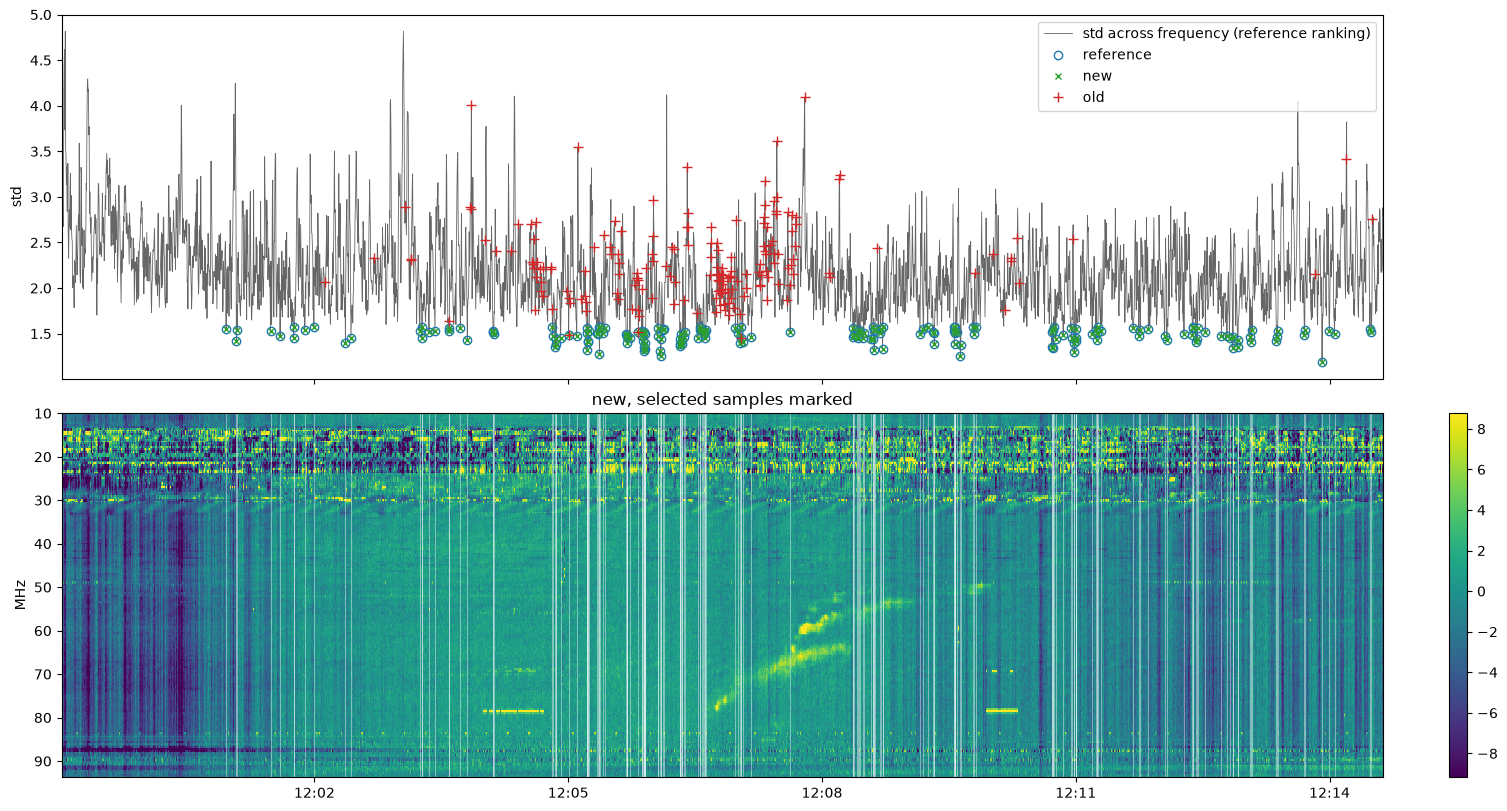

In [6]:
sd = (df - df.mean(axis=0)).std(axis=1, ddof=0)
t = mdates.date2num(df.index.to_pydatetime())

fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
a1.plot(t, sd.to_numpy(), lw=0.6, color="0.4", label="std across frequency (reference ranking)")
a1.plot(t[ref_sel], sd.to_numpy()[ref_sel], "o", ms=6, mfc="none", color="C0", label="reference")
a1.plot(t[new_sel], sd.to_numpy()[new_sel], "x", ms=5, color="C2", label="new")
a1.plot(t[old_sel], sd.to_numpy()[old_sel], "+", ms=7, color="C3", label="old")
a1.set_ylabel("std"); a1.legend(loc="upper right")
show(a2, new, "new, selected samples marked", vlim=vlim)
for x in t[new_sel]:
    a2.axvline(x, color="w", lw=0.5, alpha=0.6)
plt.show()

## Background spectra (what gets subtracted from every time sample)

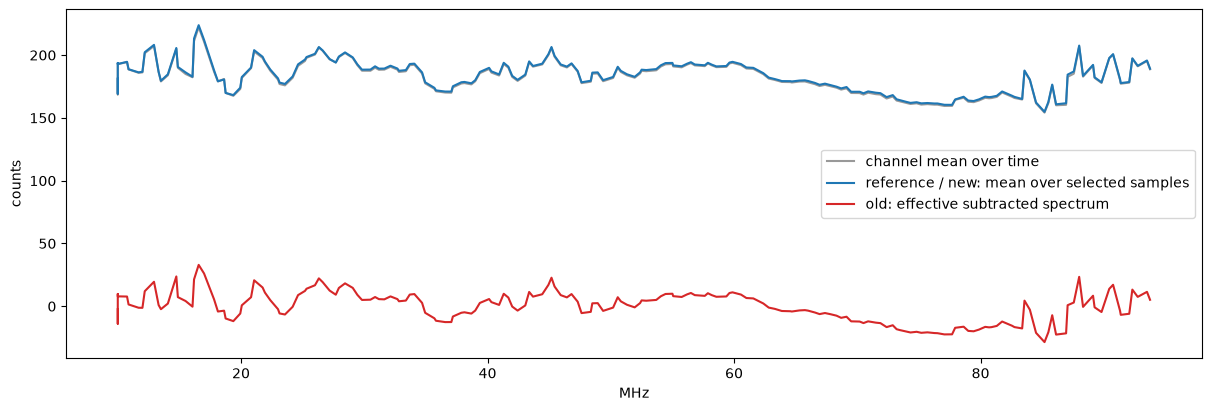

In [7]:
bg_ref = df.iloc[ref_sel].mean(axis=0)            # = per-channel mean + reference background
bg_old = (df - old).iloc[0]                    # old subtracts a constant per channel
fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(df.columns, df.mean(axis=0), color="0.6", label="channel mean over time")
ax.plot(df.columns, bg_ref, color="C0", label="reference / new: mean over selected samples")
ax.plot(df.columns, bg_old, color="C3", label="old: effective subtracted spectrum")
ax.set_xlabel("MHz"); ax.set_ylabel("counts"); ax.legend()
plt.show()

## A single time profile and a single spectrum

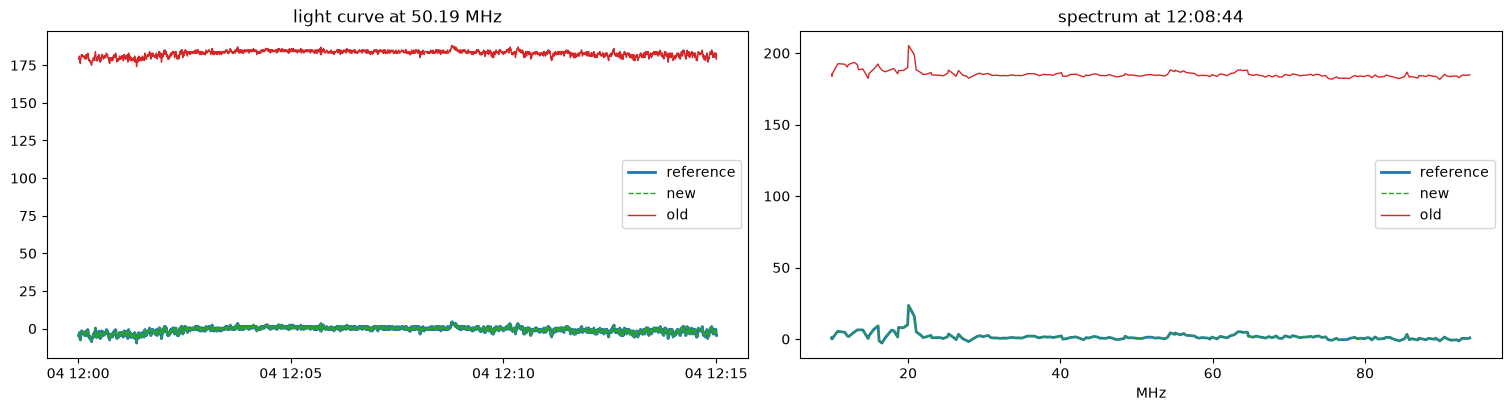

In [8]:
ch = df.columns[len(df.columns) // 2]
ti = df.index[np.nanargmax(new.mean(axis=1).to_numpy())]   # brightest time sample in the new result

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
for data, lbl, kw in [(ref, "reference", dict(lw=2, color="C0")),
                      (new, "new", dict(lw=1, ls="--", color="C2")),
                      (old, "old", dict(lw=1, color="C3"))]:
    a1.plot(data.index, data[ch], label=lbl, **kw)
    a2.plot(data.columns, data.loc[ti], label=lbl, **kw)
a1.set_title(f"light curve at {ch:.2f} MHz"); a1.legend()
a2.set_title(f"spectrum at {ti:%H:%M:%S}"); a2.set_xlabel("MHz"); a2.legend()
plt.show()

## Synthetic check with a known quiet period

Bandpass + noise everywhere, a low-noise stretch (samples 100–129) and a broadband burst. All
selected samples should fall in the quiet stretch, which should then be ~0 in every channel.

selected (new): [100 101 103 104 106 107 108 109 111 112 114 116 117 118 119 120 122 125
 126 128 129]
selected (old): [ 25  37  47  66  80 137 139 141 189 192 224 246 310 322 325 346 359 362
 365 395]
max |new - reference| = 0.000e+00
max |new| in quiet period = 0.386
max |old| in quiet period = 152.998


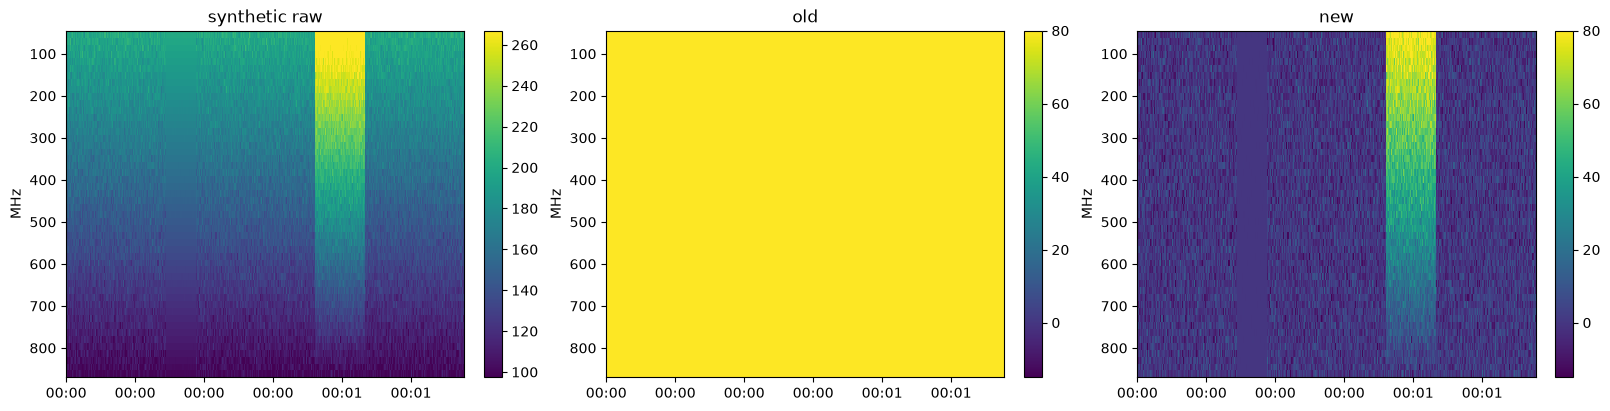

In [9]:
rng = np.random.default_rng(42)
n_time, n_freq = 400, 50
bandpass = np.linspace(100.0, 200.0, n_freq)
syn = bandpass[None, :] + rng.normal(0.0, 5.0, size=(n_time, n_freq))
syn[100:130] = bandpass[None, :] + rng.normal(0.0, 0.1, size=(30, n_freq))
syn[250:300] += np.linspace(0.0, 80.0, n_freq)[None, :]
sdf = pd.DataFrame(syn, index=pd.date_range("2024-01-01", periods=n_time, freq="250ms"),
                   columns=np.linspace(870.0, 45.0, n_freq))

s_new = subtract_low_signal_noise_background(sdf)
s_ref, s_sel = constbacksub_reference(sdf.to_numpy().T)
s_old = old_subtract_low_signal_noise_background(sdf)
print("selected (new):", selected_new(sdf))
print("selected (old):", selected_old(sdf))
print(f"max |new - reference| = {np.abs(s_new.to_numpy() - s_ref.T).max():.3e}")
print(f"max |new| in quiet period = {np.abs(s_new.iloc[100:130].to_numpy()).max():.3f}")
print(f"max |old| in quiet period = {np.abs(s_old.iloc[100:130].to_numpy()).max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
show(axes[0], sdf, "synthetic raw")
show(axes[1], s_old, "old", vlim=(-15, 80))
show(axes[2], s_new, "new", vlim=(-15, 80))
plt.show()

## Try it yourself

Change `PERCENTILE` or `FITS_FILE` in the first code cell and re-run all cells, or add NaNs to `df`
and re-run the comparison cells to see how missing data is handled (means and stds skip NaNs; time
samples whose std is NaN are never selected).